<a href="https://colab.research.google.com/github/jp-dotosme/CCADMACL-COM242ML-Dotosme/blob/main/Demo_2_Feature_Selection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DEMO — Feature Selection

In this demo we walk through the **same steps as Exercise 2**, but with a different dataset: **Red Wine Quality**.

**Goal:** Predict if a red wine is **good** (rated **6 or higher** out of 10 by wine experts) using 11 lab measurements, and find out **which measurements really matter**.

Not every column in a dataset is useful. Remember the car example from the lecture: a car is not crushed because of its *previous owner*, so we drop that column. **Feature selection** keeps only the relevant features. This can:

- prevent the model from learning from **noise**,
- **improve** (or keep) the accuracy,
- **reduce** training time.

We try the **three feature selection methods** from the lecture:

| Method | When does it choose the features? | How it works | What we use |
|---|---|---|---|
| **Filter** | **Before** training (a pre-processing step) | Gives each feature a **score** based on how related it is to the label. Does **not** use a learning algorithm. | `SelectKBest` + ANOVA F-test (`f_classif`) |
| **Wrapper** | **Around** the model | **Trains the model again and again** on different subsets of features, and keeps the subset that gives the best result. | `RFECV` (Recursive Feature Elimination + Cross-Validation) |
| **Embedded** | **During** training | The model has its **own built-in way** to measure how important each feature is. | `RandomForestClassifier` + `SelectFromModel` |

## Our Goal

At the end of this demo, the results answer **three questions**:

1. **Which lab measurements really decide if a wine is good?** Each method gives a list of selected features. `Alcohol`, `VolatileAcidity`, `Sulphates` and `TotalSO2` are chosen by **every** method.
2. **How many features do we really need?** Only **4 to 8 of the 11** features.
3. **Does using fewer features make the model worse?** **No.** Every method gets the **same or slightly higher** accuracy than the baseline (about **0.74**):

| Model | Number of features | Test accuracy |
|---|---|---|
| Baseline (all features) | 11 | about **0.74** |
| Part 1 — Filter | 4 | about **0.74** |
| Part 2 — Wrapper | 8 | about **0.75** |
| Part 3 — Embedded | 4 | about **0.74** |

**Final result:** the comparison in Section 13 shows that a model with **only 4 relevant features** predicts wine quality as well as the model with all 11.

Dataset: https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009

---

## Objectives

By the end of this demo, you should be able to:

1. Explain the difference between the **filter**, **wrapper** and **embedded** methods.
2. Follow the steps to select features with `SelectKBest`, `RFECV` and `SelectFromModel`.
3. Train a model on the selected features only and measure its **accuracy**.
4. Read the **visualizations** of each method.
5. Apply the same steps to a new dataset in **Exercise 2**.

## Expected Outcomes

After running every cell, you should see:

| Section | Expected outcome |
|---|---|
| 3 | Baseline accuracy with **all 11 features**: about **0.74** |
| 4–6 | **Filter:** 4 features (`VolatileAcidity`, `TotalSO2`, `Sulphates`, `Alcohol`), accuracy about **0.74**, and a bar chart of F-scores |
| 7–9 | **Wrapper:** best number = **8** features, accuracy about **0.75**, and a line chart of accuracy vs number of features |
| 10–12 | **Embedded:** the same 4 features as the filter method, accuracy about **0.74**, and a bar chart of importances with a red threshold line |
| 13 | A comparison table and bar chart of all methods |

In [1]:
import os, glob                       # Tools for finding files on the computer
import numpy as np                    # Math with arrays
import pandas as pd                   # Tables (DataFrames)
import matplotlib.pyplot as plt       # Plotting
import kagglehub                      # Downloads datasets from Kaggle

from sklearn.model_selection import train_test_split, StratifiedKFold  # Split data / cross-validation folds
from sklearn.preprocessing import StandardScaler                       # Puts all features on the same scale
from sklearn.linear_model import LogisticRegression                    # The classifier we use to test each feature set
from sklearn.ensemble import RandomForestClassifier                    # Tree model used by the embedded method
from sklearn.metrics import accuracy_score                             # Share of correct predictions
from sklearn.feature_selection import SelectKBest, f_classif           # Filter method: keep the K best-scoring features
from sklearn.feature_selection import RFECV                            # Wrapper method: Recursive Feature Elimination + Cross-Validation
from sklearn.feature_selection import SelectFromModel                  # Embedded method: keep features the model finds important

In [2]:
# Downloads the dataset from Kaggle automatically (no API key needed)
datasetpath = kagglehub.dataset_download("uciml/red-wine-quality-cortez-et-al-2009")  # Download and get the folder where it was saved
dataseturl = glob.glob(os.path.join(datasetpath, "**", "winequality-red.csv"), recursive=True)[0]  # Find the CSV file inside that folder

Using Colab cache for faster access to the 'red-wine-quality-cortez-et-al-2009' dataset.


## 1. Load the Dataset

We read the CSV file into a pandas DataFrame called `df` and look at the first 5 rows.

Each row is one red wine. The first 11 columns are lab measurements. The `quality` column is the score (0 to 10) that wine experts gave after tasting it.

In [3]:
df = pd.read_csv(dataseturl)  # Read the CSV file into a table called df
df.head()                     # Show the first 5 rows

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 2. Prepare the Data

We give every column a short name, and turn the expert score into a **yes/no label**: a wine is **good** if its score is **6 or higher**.

| Column | Meaning | Column | Meaning |
|---|---|---|---|
| `FixedAcidity` | main acids in the wine | `TotalSO2` | total preservative (sulfur dioxide) |
| `VolatileAcidity` | vinegar-like sourness (too much tastes bad) | `Density` | how heavy the wine is compared to water |
| `CitricAcid` | adds freshness and flavor | `pH` | acidity level (lower = more acidic) |
| `Sugar` | sugar left after fermentation (sweetness) | `Sulphates` | additive that keeps the wine fresh |
| `Salt` | amount of salt | `Alcohol` | alcohol content (%) |
| `FreeSO2` | free preservative (sulfur dioxide) | | |

**Label:** `GoodWine`: 0 = not good (score 5 or lower), 1 = good (score 6 or higher). About half of the wines are good, so the two groups are balanced.

Then we:

- split the data into **80% training** (`X_train`, `y_train`) and **20% testing** (`X_test`, `y_test`),
- **scale** the features with `StandardScaler`, so every feature has a similar range. Without this, a feature with big numbers (like `TotalSO2`, up to ~290) would look more important than a feature with small numbers (like `Density`, around 0.99) just because of its size,
- set `k = 4`: the number of features the filter method will keep.

In [4]:
data = df.rename(columns={                         # Give every column a short, easy name
    "fixed acidity":        "FixedAcidity",     # Main acids in the wine (they do not evaporate)
    "volatile acidity":     "VolatileAcidity",  # Vinegar-like sourness (too much = bad taste)
    "citric acid":          "CitricAcid",       # Adds freshness and flavor
    "residual sugar":       "Sugar",            # Sugar left after fermentation (sweetness)
    "chlorides":            "Salt",             # Amount of salt
    "free sulfur dioxide":  "FreeSO2",          # Free preservative (sulfur dioxide)
    "total sulfur dioxide": "TotalSO2",         # Total preservative (sulfur dioxide)
    "density":              "Density",          # How heavy the wine is compared to water
    "pH":                   "pH",               # Acidity level (lower = more acidic)
    "sulphates":            "Sulphates",        # Additive that helps keep the wine fresh
    "alcohol":              "Alcohol",          # Alcohol content (%)
    "quality":              "Quality",          # Expert taste score from 0 to 10
})
data["GoodWine"] = (data.pop("Quality") >= 6).astype(int)  # The label: 1 = good wine (score 6 or more), 0 = not good

label = "GoodWine"                                 # Name of the column we want to predict
features = [c for c in data.columns if c != label]  # Every other column is a feature
k = 4                                               # How many features the filter method will keep

# 80% training / 20% testing; stratify keeps the same mix of classes in both parts
train, test = train_test_split(data, test_size=0.2, stratify=data[label], random_state=42)

scaler = StandardScaler()                                # Rescales each feature to mean 0 and spread 1
X_train = pd.DataFrame(scaler.fit_transform(train[features]), columns=features, index=train.index)  # Learn the scale from TRAIN data only, then apply it
X_test  = pd.DataFrame(scaler.transform(test[features]),      columns=features, index=test.index)   # Apply the same scale to the test data
y_train, y_test = train[label], test[label]              # The answers (labels) for train and test

print("Train:", X_train.shape, " Test:", X_test.shape)   # (rows, columns) of each part
print("Features:", features)                             # List all feature names
data.head()                                              # Show the first 5 rows of the renamed table

Train: (1279, 11)  Test: (320, 11)
Features: ['FixedAcidity', 'VolatileAcidity', 'CitricAcid', 'Sugar', 'Salt', 'FreeSO2', 'TotalSO2', 'Density', 'pH', 'Sulphates', 'Alcohol']


,FixedAcidity,VolatileAcidity,CitricAcid,Sugar,Salt,FreeSO2,TotalSO2,Density,pH,Sulphates,Alcohol,GoodWine
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,0


## 3. Baseline: All Features

Before selecting anything, we train `LogisticRegression` on **all 11 features**. This accuracy (`acc_all`) is our **baseline**: we compare every feature selection method with it.

We use the **same classifier** (`LogisticRegression(max_iter=1000)`) for every method, so the only thing that changes is **which features** it gets.

In [5]:
# Baseline: train Logistic Regression on ALL features, so we have something to compare with
model_all = LogisticRegression(max_iter=1000)    # Create the classifier (max_iter = enough steps to finish learning)
model_all.fit(X_train, y_train)                  # Train it on all the features
pred_all = model_all.predict(X_test)             # Predict the labels of the test wines
acc_all = accuracy_score(y_test, pred_all)       # Compare predictions with the real answers
print("Number of features:", len(features))       # How many features we used
print("Baseline test accuracy (all features):", round(acc_all, 4))  # Print the accuracy

Number of features: 11
Baseline test accuracy (all features): 0.7406


# PART 1 — FILTER METHOD: SelectKBest + ANOVA F-test

A filter method looks at each feature **on its own** and gives it a **score**: how strongly is this feature related to the label?
It does this **before** training, and it does **not** use any learning algorithm. Then it keeps the features with the highest scores.

We use `SelectKBest` with the **ANOVA F-test** (`f_classif`). The F-score is high when the average value of a feature is very different between the groups (not good vs good wine).

## 4. Score the Features

**Step 1:** Create the selector with `SelectKBest(score_func=f_classif, k=k)` and call it `selector_filter`.

**Step 2:** Run it with `selector_filter.fit(X_train, y_train)`. This computes the F-score of every feature. No model is trained.

In [6]:
# Filter method: score every feature with the ANOVA F-test and keep the k best
selector_filter = SelectKBest(score_func=f_classif, k=k)  # Create the selector (k = 4 features)
selector_filter.fit(X_train, y_train)                     # Score each feature against the label (no model is trained here)

SelectKBest(k=4)

## 5. Select and Evaluate

**Step 1:** `selector_filter.get_support()` gives `True` for the selected features and `False` for the others. We use it to get the **names** of the selected features and save them as `cols_filter`.

**Step 2:** Train `LogisticRegression` using **only** `X_train[cols_filter]`, predict `X_test[cols_filter]`, and save the accuracy as `acc_filter`.

In [7]:
cols_filter = list(X_train.columns[selector_filter.get_support()])  # get_support() = True/False per feature -> keep the names marked True
print("Selected features:", cols_filter)                             # Show the chosen features

model_filter = LogisticRegression(max_iter=1000)                     # Same classifier as the baseline
model_filter.fit(X_train[cols_filter], y_train)                      # Train it using ONLY the selected features
pred_filter = model_filter.predict(X_test[cols_filter])              # Predict the test wines (same selected features)
acc_filter = accuracy_score(y_test, pred_filter)                     # Compute the accuracy
print("Filter method test accuracy:", round(acc_filter, 4))          # Print it

Selected features: ['VolatileAcidity', 'TotalSO2', 'Sulphates', 'Alcohol']
Filter method test accuracy: 0.7438


## 6. Visualize the Filter Method

We draw one bar per feature. The longer the bar, the higher the F-score.

**Step 1:** Put `selector_filter.scores_` in a pandas Series with the feature names, and sort it.

**Step 2:** Color the selected features **blue** and the dropped features **gray**, and draw a horizontal bar chart with `ax.barh`.

**Step 3:** Add the score at the end of each bar, axis labels and a title.

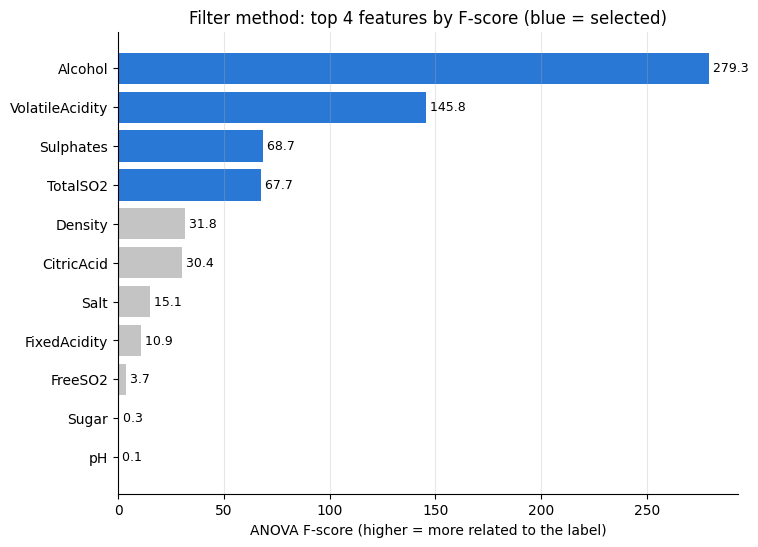

In [8]:
# 1. Put the F-score of every feature in a Series and sort it (smallest first, so the biggest bar is on top)
scores_filter = pd.Series(selector_filter.scores_, index=features).sort_values()

# 2. Blue bar = selected feature, gray bar = dropped feature
bar_colors = ["#2a78d6" if f in cols_filter else "#c4c4c4" for f in scores_filter.index]

fig, ax = plt.subplots(figsize=(8, 6))                                 # Create the figure
ax.barh(scores_filter.index, scores_filter.values, color=bar_colors)  # One horizontal bar per feature
for i, v in enumerate(scores_filter.values):                          # Go through every bar...
    ax.text(v, i, f" {v:.1f}", va="center", fontsize=9)               # ...and write its score at the end of the bar

# 3. Labels and title
ax.set_xlabel("ANOVA F-score (higher = more related to the label)")   # x-axis label
ax.set_title(f"Filter method: top {k} features by F-score (blue = selected)")  # Title
ax.grid(axis="x", alpha=0.3)                                          # Light vertical grid lines
ax.spines[["top", "right"]].set_visible(False)                        # Hide the top and right borders
plt.show()                                                            # Display the chart

### What the plot shows

- **Each bar is one feature.** Its length is the F-score: how different that feature is between good and not-good wines.
- **`Alcohol` has by far the highest score.** In this dataset, wines with more alcohol usually get better scores.
- **`VolatileAcidity` comes second.** Too much of it makes the wine taste like vinegar, so good wines have less of it.
- **`Sulphates` and `TotalSO2` complete the top 4** (the blue, selected features).
- **`pH` and `Sugar` have almost zero scores.** Surprisingly, sweetness says almost nothing about whether a red wine is good, so these are dropped.

**Key idea:** a filter method only looks at the **data**, one feature at a time. It is **fast** and works with any model, but it does not check how the features work **together**.

# PART 2 — WRAPPER METHOD: RFECV

A wrapper method **trains the model** on a subset of features, checks the result, then **adds or removes** features and trains again.

We use **Recursive Feature Elimination (RFE)**:

1. Train the model on all features.
2. Remove the **weakest** feature (the one with the smallest weight in the model).
3. Train again on the remaining features. Repeat until only 1 feature is left.

`RFECV` adds **Cross-Validation (CV)**: for every number of features, it checks the accuracy on 5 different train/validation splits. It then picks the **number of features** with the best average accuracy. So we do not have to choose `k` ourselves.

## 7. Run RFE with Cross-Validation

**Step 1:** Create `RFECV` with `LogisticRegression(max_iter=1000)` as the model, `step=1` (remove 1 feature per round), `cv=StratifiedKFold(5)` and `scoring="accuracy"`. Call it `rfecv`.

**Step 2:** Run it with `rfecv.fit(X_train, y_train)`, and print `rfecv.n_features_`, the best number of features.

In [9]:
# Wrapper method: train the model, remove the weakest feature, repeat, and use cross-validation to find the best number of features
rfecv = RFECV(
    estimator=LogisticRegression(max_iter=1000),  # The model that is trained again and again
    step=1,                                       # Remove 1 feature per round
    cv=StratifiedKFold(5),                        # Check each feature set with 5-fold cross-validation
    scoring="accuracy",                           # Compare feature sets by accuracy
)
rfecv.fit(X_train, y_train)                       # Run the whole elimination process on the training data
print("Best number of features:", rfecv.n_features_)  # The number of features with the best cross-validation accuracy

Best number of features: 8


## 8. Select and Evaluate

Same as Section 5, but the True/False list is `rfecv.support_`. We save the selected names as `cols_wrapper` and the accuracy as `acc_wrapper`.

In [10]:
cols_wrapper = list(X_train.columns[rfecv.support_])          # support_ = True/False per feature -> keep the names marked True
print("Selected features:", cols_wrapper)                      # Show the chosen features

model_wrapper = LogisticRegression(max_iter=1000)              # Same classifier as the baseline
model_wrapper.fit(X_train[cols_wrapper], y_train)              # Train it using ONLY the selected features
pred_wrapper = model_wrapper.predict(X_test[cols_wrapper])     # Predict the test wines
acc_wrapper = accuracy_score(y_test, pred_wrapper)             # Compute the accuracy
print("Wrapper method test accuracy:", round(acc_wrapper, 4))  # Print it

Selected features: ['FixedAcidity', 'VolatileAcidity', 'CitricAcid', 'Salt', 'FreeSO2', 'TotalSO2', 'Sulphates', 'Alcohol']
Wrapper method test accuracy: 0.75


## 9. Visualize the Wrapper Method

We plot the **cross-validation accuracy** for **every number of features** that RFECV tried.

**Step 1:** Take `n_features`, `mean_test_score` and `std_test_score` from `rfecv.cv_results_`.

**Step 2:** Draw a line with error bars using `ax.errorbar`.

**Step 3:** Draw a red dashed line at the best number of features with `ax.axvline`, and add labels, a title and a legend.

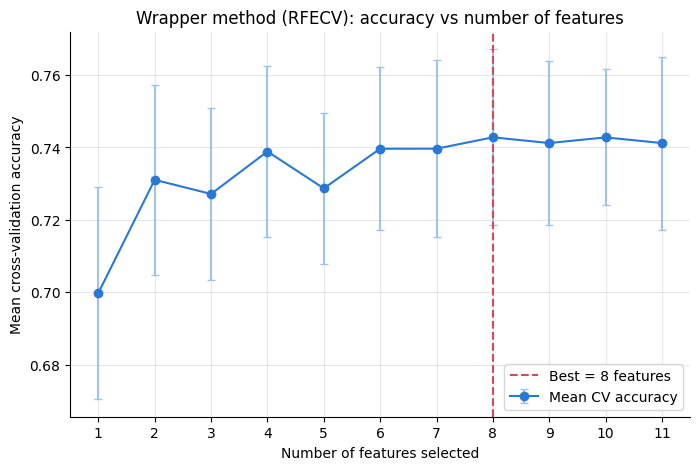

In [11]:
# 1. Results for every number of features that RFECV tried
n_feats  = rfecv.cv_results_["n_features"]       # x: how many features were used
mean_acc = rfecv.cv_results_["mean_test_score"]  # y: average accuracy over the 5 folds
std_acc  = rfecv.cv_results_["std_test_score"]   # error bar: how much the accuracy changed between folds

# 2. Line with error bars
fig, ax = plt.subplots(figsize=(8, 5))                                      # Create the figure
ax.errorbar(n_feats, mean_acc, yerr=std_acc, marker="o", color="#2a78d6",   # Accuracy for each number of features
            ecolor="#9fc3ea", capsize=3, label="Mean CV accuracy")

# 3. Mark the best number of features, then add labels
ax.axvline(rfecv.n_features_, color="#d1495b", linestyle="--",              # Red dashed line at the best number
           label=f"Best = {rfecv.n_features_} features")
ax.set_xticks(n_feats)                                                      # Show every feature count on the x-axis
ax.set_xlabel("Number of features selected")                                # x-axis label
ax.set_ylabel("Mean cross-validation accuracy")                             # y-axis label
ax.set_title("Wrapper method (RFECV): accuracy vs number of features")     # Title
ax.grid(alpha=0.3)                                                          # Light grid
ax.spines[["top", "right"]].set_visible(False)                              # Hide the top and right borders
ax.legend(loc="lower right")                                                # Legend
plt.show()                                                                  # Display the chart

### What the plot shows

- **Each dot is one number of features.** Its height is the average accuracy over the 5 cross-validation folds. The vertical error bar shows how much the accuracy changed from fold to fold.
- **With only 1 feature (`Alcohol`, the last feature RFE removes), the accuracy is already about 0.70.** Alcohol alone tells us a lot.
- **The accuracy rises quickly up to about 4 features, then the line stays almost flat** (between about 0.73 and 0.74). Adding more features after that barely helps.
- **The best average is at 8 features** (red dashed line), but it is only a tiny bit higher than with 4. The error bars overlap, so 4 and 8 features are almost equally good.
- **The last 4 features RFE keeps are `Alcohol`, `VolatileAcidity`, `TotalSO2` and `Sulphates`**: the same 4 the filter method chose.

**Key idea:** a wrapper method **uses the model itself** to judge each feature set. It checks how features work **together**, but it is **slower**, because it trains the model many times.

# PART 3 — EMBEDDED METHOD: Random Forest + SelectFromModel

In an embedded method, feature selection happens **during training**. The model has its **own built-in** way to measure how useful each feature is.

A **Random Forest** is a group of decision trees. While it trains, it records how much each feature helps the trees split the data. This is the **feature importance** (all importances add up to 1).

`SelectFromModel` then keeps the features whose importance is **above the average**. Lasso / Ridge regression and decision trees are other examples of embedded methods.

## 10. Train the Model

**Step 1:** Create `RandomForestClassifier(n_estimators=300, random_state=42)` and call it `rf`.

**Step 2:** Train it with `rf.fit(X_train, y_train)`. The importances are computed during this training.

In [12]:
# Embedded method: a Random Forest measures how important each feature is WHILE it trains
rf = RandomForestClassifier(n_estimators=300, random_state=42)  # 300 decision trees; random_state = same result every run
rf.fit(X_train, y_train)                                        # Train the forest (feature importances are computed here)

RandomForestClassifier(n_estimators=300, random_state=42)

## 11. Select and Evaluate

**Step 1:** Create `SelectFromModel(rf, prefit=True)` and call it `sfm`. `prefit=True` means "the model is already trained, just use it".

**Step 2:** Use `sfm.get_support()` to get the selected names (`cols_embedded`), then train `LogisticRegression` on them and save the accuracy as `acc_embedded`.

In [13]:
sfm = SelectFromModel(rf, prefit=True)                           # Use the trained forest; keep features with above-average importance
cols_embedded = list(X_train.columns[sfm.get_support()])         # Names of the kept features
print("Selected features:", cols_embedded)                       # Show them

model_embedded = LogisticRegression(max_iter=1000)               # Same classifier as the baseline
model_embedded.fit(X_train[cols_embedded], y_train)              # Train it using ONLY the selected features
pred_embedded = model_embedded.predict(X_test[cols_embedded])    # Predict the test wines
acc_embedded = accuracy_score(y_test, pred_embedded)             # Compute the accuracy
print("Embedded method test accuracy:", round(acc_embedded, 4))  # Print it

Selected features: ['VolatileAcidity', 'TotalSO2', 'Sulphates', 'Alcohol']
Embedded method test accuracy: 0.7438


## 12. Visualize the Embedded Method

**Step 1:** Put `rf.feature_importances_` in a pandas Series with the feature names, and sort it.

**Step 2:** Color the selected features **green** and the dropped features **gray**, and draw a horizontal bar chart.

**Step 3:** Draw the **threshold** (the average importance, `importances.mean()`) as a red dashed line, and add labels, a title and a legend.

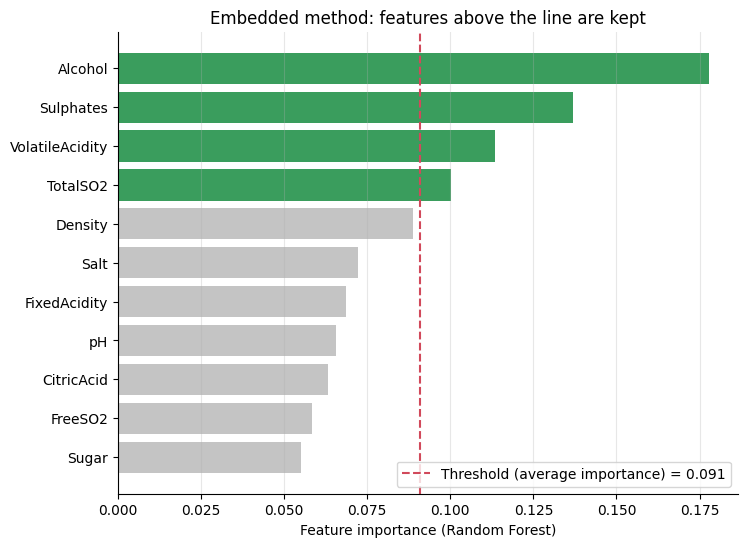

In [14]:
# 1. Put the importance of every feature in a Series and sort it
importances = pd.Series(rf.feature_importances_, index=features).sort_values()

# 2. Green bar = selected feature, gray bar = dropped feature
bar_colors = ["#3a9d5d" if f in cols_embedded else "#c4c4c4" for f in importances.index]

fig, ax = plt.subplots(figsize=(8, 6))                             # Create the figure
ax.barh(importances.index, importances.values, color=bar_colors)  # One horizontal bar per feature

# 3. Threshold line + labels
threshold = importances.mean()                                     # SelectFromModel's default cut-off = the average importance
ax.axvline(threshold, color="#d1495b", linestyle="--",             # Red dashed line at the cut-off
           label=f"Threshold (average importance) = {threshold:.3f}")
ax.set_xlabel("Feature importance (Random Forest)")                # x-axis label
ax.set_title("Embedded method: features above the line are kept")  # Title
ax.grid(axis="x", alpha=0.3)                                       # Light vertical grid lines
ax.spines[["top", "right"]].set_visible(False)                     # Hide the top and right borders
ax.legend(loc="lower right")                                       # Legend
plt.show()                                                         # Display the chart

### What the plot shows

- **Each bar is one feature's importance**, as the Random Forest learned it while training.
- **The red dashed line is the threshold** (the average importance, 1 / 11 ≈ 0.091). Features to the right of the line are kept.
- **`Alcohol` is again the most important feature**, followed by `Sulphates`, `VolatileAcidity` and `TotalSO2`: the **same 4 features** as the filter method, even though the two methods work in very different ways.
- **`Density` is just below the line**, so it is dropped. A feature close to the threshold could go either way if the data or the model changes a little.

**Key idea:** an embedded method gets feature selection "for free" **while the model trains**. It is faster than a wrapper method and, unlike a filter method, it can see how features work together.

## 13. Compare the Methods

Finally, we put the baseline and the three methods side by side.

,Method,Type,Num Features,Selected Features,Test Accuracy
0,All features (baseline),None,11,all,0.7406
1,Filter: SelectKBest,Filter,4,"VolatileAcidity, TotalSO2, Sulphates, Alcohol",0.7438
2,Wrapper: RFECV,Wrapper,8,"FixedAcidity, VolatileAcidity, CitricAcid, Sal...",0.7500
3,Embedded: Random Forest,Embedded,4,"VolatileAcidity, TotalSO2, Sulphates, Alcohol",0.7438


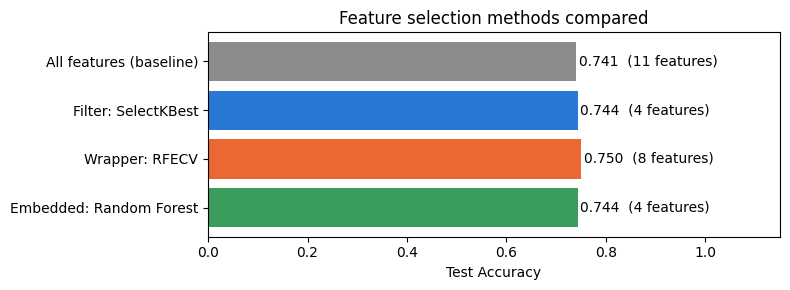

In [15]:
# Compares the baseline (all features) with the three feature selection methods
comparison = pd.DataFrame({
    "Method": ["All features (baseline)", "Filter: SelectKBest", "Wrapper: RFECV", "Embedded: Random Forest"],  # Method names
    "Type":   ["None", "Filter", "Wrapper", "Embedded"],                                                       # Method family
    "Num Features": [len(features), len(cols_filter), len(cols_wrapper), len(cols_embedded)],                  # How many features each one used
    "Selected Features": ["all", ", ".join(cols_filter), ", ".join(cols_wrapper), ", ".join(cols_embedded)],  # Which features
    "Test Accuracy": [acc_all, acc_filter, acc_wrapper, acc_embedded],                                         # Accuracy on the test set
}).round(4)                                                    # Round numbers to 4 decimals
display(comparison)                                            # Show the table

type_colors = {"None": "#8c8c8c", "Filter": "#2a78d6", "Wrapper": "#eb6834", "Embedded": "#3a9d5d"}  # One color per method type
plt.figure(figsize=(8, 3))                                                                          # Create the figure
plt.barh(comparison["Method"], comparison["Test Accuracy"], color=comparison["Type"].map(type_colors))  # One bar per method
for i, (v, n) in enumerate(zip(comparison["Test Accuracy"], comparison["Num Features"])):          # For every bar...
    plt.text(v + 0.005, i, f"{v:.3f}  ({n} features)", va="center")                                # ...write its accuracy and number of features
plt.xlim(0, 1.15)                                                                                   # Leave room for the text
plt.xlabel("Test Accuracy")                                                                         # x-axis label
plt.title("Feature selection methods compared")                                                     # Title
plt.gca().invert_yaxis()                                                                            # Baseline on top
plt.tight_layout()                                                                                  # Fit everything nicely
plt.show()                                                                                          # Display the chart

### What the comparison shows

- **The filter and embedded methods kept only 4 of the 11 features** and got the same accuracy as the baseline (about 0.74). Fewer features, same result, and a simpler, faster model.
- **The wrapper kept 8 features** and got the highest accuracy (0.75), but only by a little: on 320 test wines, 0.01 is about 3 wines.
- **`Alcohol`, `VolatileAcidity`, `Sulphates` and `TotalSO2` were chosen by every method.** When different methods agree, we can be more confident that a feature really matters.
- **`Sugar`, `Density` and `pH` were dropped by every method.** They add little or nothing for this task.

Now try the same steps on a new dataset in **Exercise 2**!